# 02 — Yield Curve : construction et analyse de la courbe des taux

Ce notebook construit et analyse une courbe des taux à partir de taux au pair observés, en dérivant :

1. Les **facteurs d'actualisation** (DF) et les **taux zéro-coupon** par *bootstrapping*.
2. Les **taux forward 1 an** implicites.
3. Le **pricing d'obligations** à partir de la courbe (au lieu d'un YTM unique).
4. La comparaison entre YTM, taux au pair et taux zéro-coupon.
5. La visualisation de courbes synthétiques (pentue vs inversée).
6. L'analyse d'une courbe réelle US Treasury (données FRED) et de sa pente 10s2s.

**Formules clés :**
- Facteur d'actualisation : $DF(t) = \dfrac{1}{(1+z_t)^t}$
- Taux forward entre $t_1$ et $t_2$ : $f_{t_1,t_2} = \dfrac{(1+z_{t_2})^{t_2}}{(1+z_{t_1})^{t_1}} - 1$

## 1. Imports et données

On importe les fonctions du module `curve` :
- `bootstrap_par_curve(mats, par)` : construit DF et zéro-coupon depuis les taux au pair.
- `interp_zero`, `discount_factor` : interpolation et actualisation sur la courbe.
- `price_with_curve(t, cf, mats, zeros)` : prix d'une obligation à partir de la courbe zéro-coupon.
- `forward_rate(t1, t2, mats, zeros)` : taux forward implicite entre deux maturités.

On définit une courbe au pair synthétique sur maturités 1 à 10 ans, croissante de 2.5 % à 3.7 % — profil typique d'une courbe normale (pentue).

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bonds import cashflows, bond_price, ytm
from curve import (bootstrap_par_curve, interp_zero, discount_factor,
                   price_with_curve, forward_rate)

mats = np.arange(1, 11)
par = np.array([0.025, 0.027, 0.029, 0.031, 0.0325, 0.034, 0.035, 0.036, 0.0365, 0.037])

## 2. Bootstrapping de la courbe zéro-coupon

À partir des taux au pair (maturités 1 à 10 ans), on reconstruit toute la structure par terme :

- **DF (Discount Factor)** : prix aujourd'hui d'un zéro-coupon de nominal 1 à maturité $t$.
- **zéro-coupon** : taux actuariel $z_t$ tel que $DF(t) = (1+z_t)^{-t}$.
- **forward 1 an** : taux forward implicite entre $t-1$ et $t$, calculé à partir des zéro-coupon.

Observations attendues :
- Le premier zéro-coupon égale le premier taux au pair (maturité 1 an, un seul flux).
- Les zéro-coupon sont légèrement **au-dessus** des taux au pair (effet du coupon reinvesti).
- Les forwards sont **au-dessus** des zéro-coupon quand la courbe est croissante.

In [2]:
df, zeros = bootstrap_par_curve(mats, par)
fwd = [zeros[0]] + [forward_rate(n - 1, n, mats, zeros) for n in mats[1:]]

table = pd.DataFrame({"maturité": mats, "taux au pair": par, "DF": df,
                      "zéro-coupon": zeros, "forward 1 an": fwd})
table

,maturité,taux au pair,DF,zéro-coupon,forward 1 an
0,1,0.0250,0.975610,0.025000,0.025000
1,2,0.0270,0.948061,0.027027,0.029058
2,3,0.0290,0.917603,0.029078,0.033193
3,4,0.0310,0.884501,0.031158,0.037425
4,5,0.0325,0.851247,0.032735,0.039065
5,6,0.0340,0.816616,0.034341,0.042407
6,7,0.0350,0.783790,0.035415,0.041881
7,8,0.0360,0.750591,0.036513,0.044230
8,9,0.0365,0.720817,0.037044,0.041306
9,10,0.0370,0.691411,0.037591,0.042531


## 3. Visualisation de la courbe synthétique

On trace les trois courbes sur un même graphique :
- **Taux au pair** (cercles) : ce qu'on observe sur le marché.
- **Zéro-coupon** (carrés) : ce qu'on en déduit par bootstrapping.
- **Forward 1 an** (triangles) : anticipation implicite du marché pour l'année suivante.

Sur une courbe croissante, l'ordre attendu est : **forward > zéro > par**. Plus la courbe est pentue, plus les forwards s'écartent des zéro-coupon.

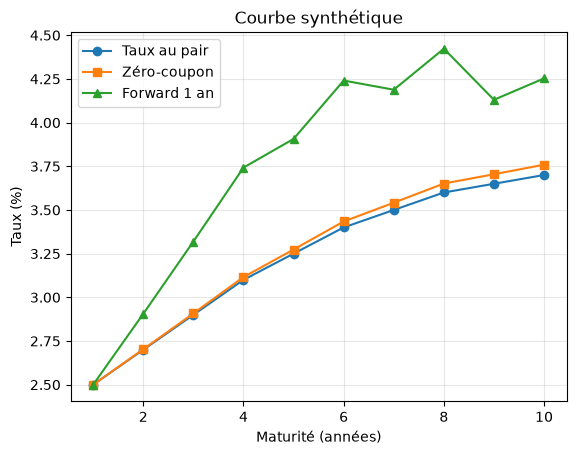

In [3]:
plt.plot(mats, par * 100, "o-", label="Taux au pair")
plt.plot(mats, zeros * 100, "s-", label="Zéro-coupon")
plt.plot(mats, np.array(fwd) * 100, "^-", label="Forward 1 an")
plt.xlabel("Maturité (années)"); plt.ylabel("Taux (%)")
plt.title("Courbe synthétique"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Validation : repricing des obligations au pair

Test de cohérence : chaque obligation fictive avec un coupon égal à son taux au pair doit être pricée à 100 lorsqu'on l'actualise avec la courbe zéro-coupon reconstruite.

C'est la **condition d'absence d'arbitrage** : si le prix dévie de 100, le bootstrapping est incorrect.

In [4]:
for n, c in zip(mats, par):
    t, cf = cashflows(100, c, n)
    print(n, round(price_with_curve(t, cf, mats, zeros), 8))   # attendu : 100

1 100.0
2 100.0
3 100.0
4 100.0
5 100.0
6 100.0
7 100.0
8 100.0
9 100.0
10 100.0


## 5. YTM vs taux au pair vs zéro-coupon

On price une obligation à coupon 5 % et maturité 7 ans **avec la courbe** (donc en actualisant chaque flux au bon zéro-coupon), puis on extrait son YTM.

L'objectif est de comparer trois notions distinctes :
- **YTM** : taux unique qui égalise le prix à la valeur actuelle des flux — c'est une moyenne pondérée des zéro-coupon.
- **Taux au pair 7 ans** : taux de coupon qui aurait prixé l'obligation à 100.
- **Zéro-coupon 7 ans** : taux d'actualisation pur pour un flux unique à 7 ans.

Observations attendues : YTM ≠ par ≠ zéro, car le YTM est un résumé imparfait de la courbe.

In [5]:
t, cf = cashflows(100, 0.05, 7)
p = price_with_curve(t, cf, mats, zeros)
y = ytm(t, cf, p)
print(f"Prix (courbe) = {p:.4f}")
print(f"YTM = {y:.4%} | taux au pair 7 ans = {par[6]:.4%} | zéro-coupon 7 ans = {zeros[6]:.4%}")

Prix (courbe) = 109.2661
YTM = 3.4854% | taux au pair 7 ans = 3.5000% | zéro-coupon 7 ans = 3.5415%


## 6. Comparaison de deux régimes de courbe

On définit deux courbes :
- **Pentue** (normale) : taux croissants avec la maturité.
- **Inversée** : taux décroissants — signal classique de ralentissement économique attendu.

Le graphique à deux panneaux permet de visualiser comment la forme de la courbe se répercute sur les zéro-coupon et les forwards. Sur une courbe inversée, les forwards passent **en dessous** des zéro-coupon, ce qui reflète des anticipations de baisse des taux.

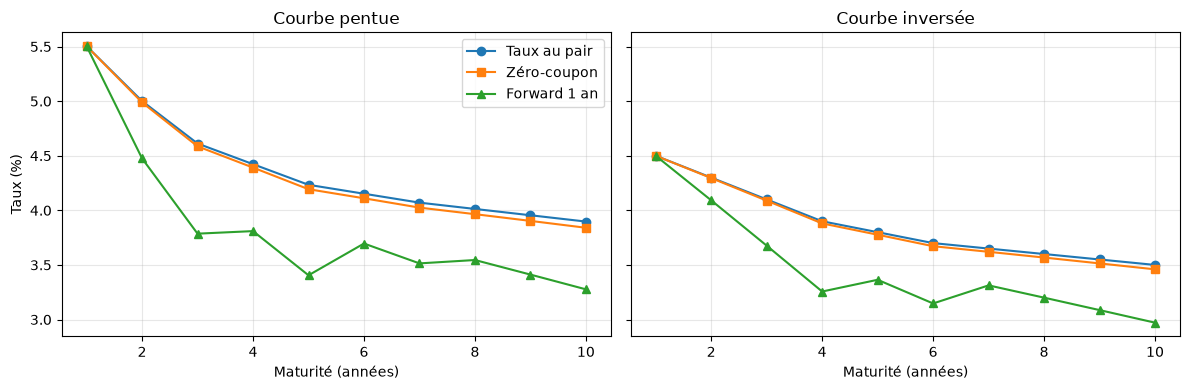

In [15]:
def curve_summary(par):
    """Retourne zéro-coupon et forward 1 an à partir de taux au pair (maturités 1..N)."""
    m = np.arange(1, len(par) + 1)
    df, zeros = bootstrap_par_curve(m, par)
    fwd = [zeros[0]] + [forward_rate(n - 1, n, m, zeros) for n in m[1:]]
    return m, zeros, np.array(fwd)

def plot_curves(ax, m, par, zeros, fwd, title):
    ax.plot(m, par * 100, "o-", label="Taux au pair")
    ax.plot(m, zeros * 100, "s-", label="Zéro-coupon")
    ax.plot(m, fwd * 100, "^-", label="Forward 1 an")
    ax.set_title(title); ax.set_xlabel("Maturité (années)")
    ax.grid(alpha=0.3)

par_inv = np.array([0.045, 0.043, 0.041, 0.039, 0.038, 0.037, 0.0365, 0.036, 0.0355, 0.035])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, p, title in zip(axes, [par, par_inv], ["Courbe pentue", "Courbe inversée"]):
    m, z, f = curve_summary(p)
    plot_curves(ax, m, p, z, f, title)
axes[0].set_ylabel("Taux (%)"); axes[0].legend()
plt.tight_layout(); plt.show()

## 7. Données réelles : US Treasury (FRED)

On télécharge les taux au pair du Trésor américain pour 6 maturités (1, 2, 3, 5, 7, 10 ans) depuis la base FRED de la Réserve fédérale de Saint-Louis.

- Les séries (`DGS1`, `DGS2`, ..., `DGS10`) sont des taux annualisés à composition semestrielle.
- On les combine en un DataFrame, on supprime les dates incomplètes, et on sauvegarde dans `../data/us_par_yields.csv`.
- On recharge depuis le CSV pour s'assurer de la reproductibilité.

Cette étape illustre un **pipeline de données réel** : téléchargement, nettoyage, stockage, rechargement.

In [20]:
import pandas as pd
from pathlib import Path

series = {1: "DGS1", 2: "DGS2", 3: "DGS3", 5: "DGS5", 7: "DGS7", 10: "DGS10"}
frames = []
for mat, sid in series.items():
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
    s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    frames.append(s.iloc[:, 0].rename(mat))

curves = pd.concat(frames, axis=1).dropna() / 100      
data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)
curves.to_csv(data_dir / "us_par_yields.csv")          
curves = pd.read_csv("../data/us_par_yields.csv", index_col=0, parse_dates=True)
curves.columns = curves.columns.astype(int)
curves.tail()


,1,2,3,5,7,10
observation_date,,,,,,
2026-10-05,0.0447,0.0484,0.0497,0.0506,0.0519,0.0531
2026-10-06,0.0446,0.0479,0.0488,0.0503,0.0515,0.0527
2026-10-07,0.0442,0.0477,0.0487,0.0503,0.0515,0.0528
2026-10-08,0.0444,0.0475,0.0485,0.0499,0.0511,0.0522
2026-10-09,0.0447,0.0480,0.0489,0.0502,0.0513,0.0524


## 8. Reconstruction des courbes US à trois dates

On sélectionne trois dates représentatives :
- **Juillet 2021** : environnement de taux bas post-COVID.
- **Juillet 2023** : cycle de hausses agressives de la Fed.
- **Date la plus récente** : état actuel de la courbe.

Pour chaque date, on interpole les taux au pair sur une **grille annuelle** (`par_on_annual_grid`), puis on bootstrappe pour obtenir zéro-coupon et forwards. Le graphique à trois panneaux permet de comparer visuellement les régimes de taux.

C'est une application directe du bootstrapping sur données réelles.

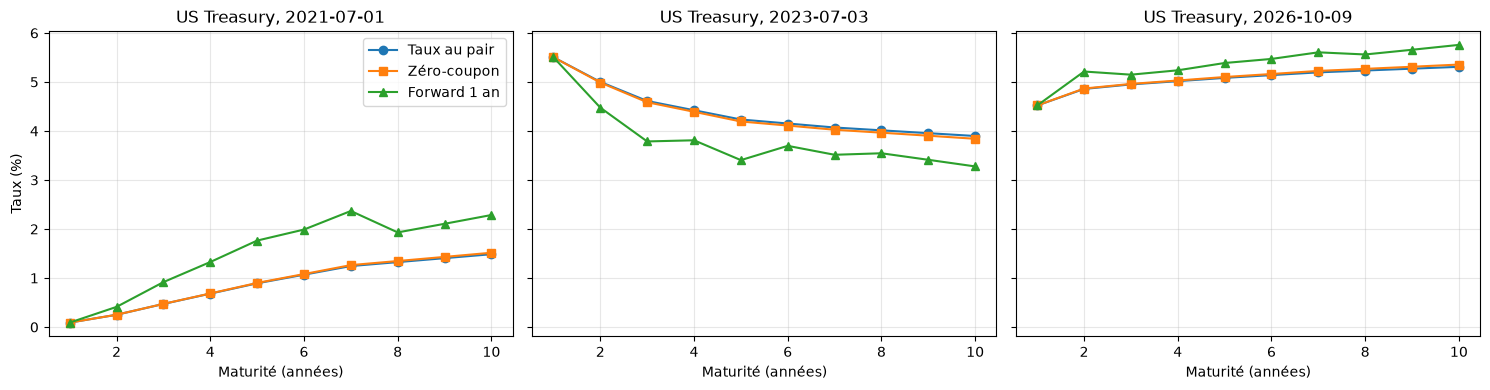

In [21]:
import importlib
import curve
curve = importlib.reload(curve)
from curve import par_on_annual_grid, bootstrap_par_curve, forward_rate

def us_curve(date):
    row = curves.loc[:date].iloc[-1]            # dernière date disponible <= date
    mats, par = par_on_annual_grid(row.index.values, row.values)
    df, zeros = bootstrap_par_curve(mats, par)
    return mats, par, zeros

dates = ["2021-07-01", "2023-07-03", str(curves.index[-1].date())]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d in zip(axes, dates):
    row = curves.loc[:d].iloc[-1]
    mats_, par_ = par_on_annual_grid(row.index.values, row.values)
    _, zeros_ = bootstrap_par_curve(mats_, par_)
    fwd_ = np.array([zeros_[0]] + [forward_rate(n - 1, n, mats_, zeros_) for n in mats_[1:]])
    plot_curves(ax, mats_, par_, zeros_, fwd_, f"US Treasury, {row.name.date()}")
axes[0].set_ylabel("Taux (%)"); axes[0].legend()
plt.tight_layout(); plt.show()

## 9. Pente de la courbe : spread 10 ans − 2 ans

Le **spread 10s2s** est l'indicateur de pente le plus suivi par les marchés :
- Spread **positif** : courbe normale (pentue).
- Spread **négatif** : courbe **inversée** — historiquement un signal avancé de récession.

On trace l'évolution temporelle du spread, avec :
- Une ligne rouge à 0 marquant le seuil d'inversion.
- Une zone rouge remplie sous 0 pour visualiser les épisodes d'inversion.

C'est un outil classique de **macro-analyse** et de **pilotage de portefeuille obligataire**.

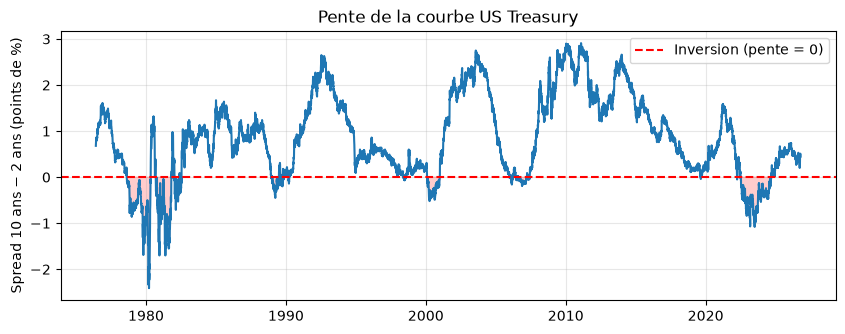

In [22]:
spread = (curves[10] - curves[2]) * 100

plt.figure(figsize=(10, 3.5))
plt.plot(spread.index, spread.values)
plt.axhline(0, color="red", linestyle="--", label="Inversion (pente = 0)")
plt.fill_between(spread.index, spread.values, 0, where=spread.values < 0, color="red", alpha=0.2)
plt.ylabel("Spread 10 ans − 2 ans (points de %)")
plt.title("Pente de la courbe US Treasury")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 10. Limites de l'interpolation

Illustration pédagogique d'un piège fréquent : lorsqu'on interpole une courbe sur une grille plus fine que les points observés, on **crée de la donnée qui n'existe pas sur le marché**.

Ici, à partir des 6 points observés (1, 2, 3, 5, 7, 10 ans), on interpole sur une grille annuelle (1 à 10 ans). Les maturités 4, 6, 8, 9 ans sont **fabriquées** par interpolation, pas observées.

- Points rouges : maturités réellement cotées (ajustées en composition annuelle).
- Ligne bleue : courbe interpolée.

**Message clé** : l'interpolation est un outil puissant mais doit être utilisée avec discernement ; le bootstrapping sur points interpolés introduit une dépendance au modèle d'interpolation choisi.

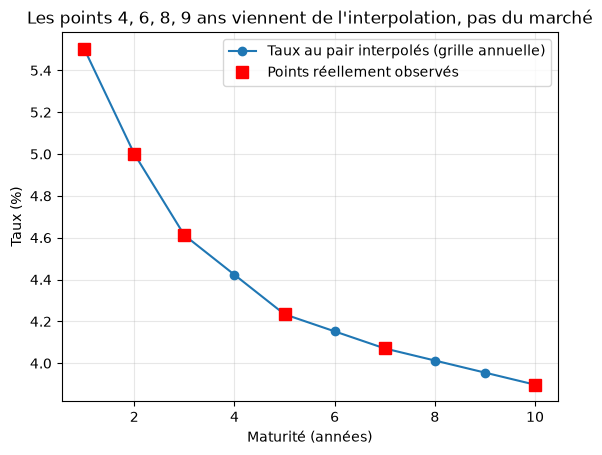

In [23]:
row = curves.loc[:"2023-07-03"].iloc[-1]
mats_, par_ = par_on_annual_grid(row.index.values, row.values)

plt.plot(mats_, par_ * 100, "o-", label="Taux au pair interpolés (grille annuelle)")
plt.plot((1 + row.index.values) - 1, ((1 + row.values / 2) ** 2 - 1) * 100,
         "rs", markersize=9, label="Points réellement observés")
plt.xlabel("Maturité (années)"); plt.ylabel("Taux (%)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Les points 4, 6, 8, 9 ans viennent de l'interpolation, pas du marché")
plt.show()